In [3]:
#Our implementation are based on the sample code by Sebastian Jaimungal, which can be found at the following link
# https://sebastian.statistics.utoronto.ca/books/algo-and-hf-trading/code/

In [4]:
# import pakacges
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimal_execution_incorplating_mm_helper as oeh
plt.style.use('seaborn-v0_8')

In [5]:
# initial various parameters
T = 60
Ndt = 6000
dt = T / Ndt
t = np.arange(0, T + dt, dt)
tau = T - t

# price jump sizes
sigma = 0.01
kappa = 100
xi = 0.01
alpha = 0.0001

lamb = 50 / 60
Nq = 10
phi = 0.001

lambL = 50/60
lambI = 60/60
alphaL = 0.005
alphaM = 0.0001
betaM = 1.5

## AC Solution
gamma=0.1
qAC = Nq * np.sinh(gamma * tau) / np.sinh(gamma * T)


In [6]:
# Inventory q Vector
q = np.arange(0, Nq + 1, 1)
df = pd.DataFrame({'t': t, 'q': qAC})
# solve the QVI  for omega LO/MO of Cartea-Jaimungal-Penalva
omega, exe = oeh.hjb_solver(t, dt, kappa, xi, phi, q, qAC, lamb, alpha)

# solve the QVI for LO/MO/MM of optimal_execution_incorpolating_mm model
h2, exe2, delta_l, delta_i, zeta \
    = oeh.hjb_solver_mm(t, dt, kappa, xi, phi, q, qAC, lambL, lambI, alpha, alphaL, alphaM, betaM)

In [7]:
#optimal  MM spread delta_i(q, t)
data_i = pd.DataFrame(delta_i)
summary_i = data_i[[1000, 2000, 3000, 4000, 5000]].describe()
display(summary_i)

,1000,2000,3000,4000,5000
count,10.000000,10.000000,10.000000,10.000000,10.000000
mean,0.019066,0.008737,0.006101,0.005100,0.004238
std,0.027264,0.015064,0.011293,0.009832,0.008436
min,-0.000183,-0.000237,-0.000280,-0.000280,-0.000280
25%,-0.000100,-0.000100,-0.000162,-0.000162,-0.000162
50%,0.006828,-0.000025,-0.000100,-0.000100,-0.000100
75%,0.026701,0.011366,0.006982,0.005328,0.004053
max,0.081992,0.044826,0.033528,0.029098,0.024883


In [8]:
#optimal  LO depth delta_l(q, t)
data_l = pd.DataFrame(delta_l)
summary_l = data_l[[1000, 2000, 3000, 4000, 5000]].describe()
display(summary_l)

,1000,2000,3000,4000,5000
count,10.000000,10.000000,10.000000,10.000000,10.000000
mean,0.021899,0.012366,0.009998,0.009119,0.008386
std,0.025388,0.013179,0.009531,0.008139,0.006852
min,0.004944,0.004822,0.004822,0.004822,0.004822
25%,0.004944,0.004944,0.004944,0.004944,0.004944
50%,0.010010,0.005005,0.004944,0.004944,0.004944
75%,0.027313,0.013580,0.010071,0.008820,0.007904
max,0.081970,0.044861,0.033752,0.029480,0.025574


,10,9,8,7,6,5,4,3,2,1,0
q,10.00,9.00,8.00,7.00,6.00,5.00,4.00,3.00,2.00,1.00,0.0
tau_{LOMO},1.47,2.86,4.51,6.54,9.17,12.87,19.07,39.12,59.19,59.99,60.0
tau_{LOMOMM},2.96,4.71,6.87,9.69,13.70,20.74,48.64,58.51,59.84,60.00,60.0


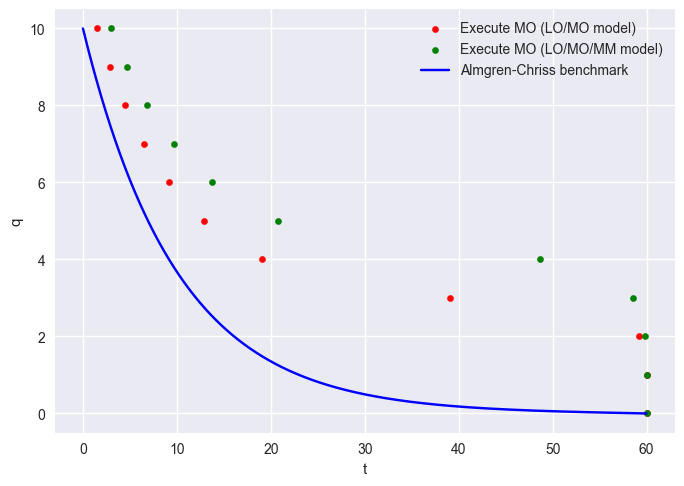

In [9]:
# obtain the optimal time at which to execute market orders
t_opt = oeh.find_opt_t(exe, t)
t_opt2 = oeh.find_opt_t(exe2, t)
optimal_exe = pd.DataFrame({'tau': t_opt, 'q':q})
optimal_exe2 = pd.DataFrame({'tau': t_opt2, 'q':q})
display(pd.DataFrame({'q': q, 'tau_{LOMO}': t_opt, 'tau_{LOMOMM}': t_opt2}).sort_values(by='q', ascending=False).transpose())

# Create a common ax for plotting
ax = optimal_exe.plot(kind='scatter', x='tau', y='q', color='r', label='Execute MO (LO/MO model)')
optimal_exe2.plot(kind='scatter', x='tau', y='q', color='g', ax=ax, label='Execute MO (LO/MO/MM model)')  # Add an additional scatter plot
# Line plot for df
df.plot(kind='line', x='t', y='q', ax=ax, color='b', label='Almgren-Chriss benchmark')
# Display the graph
plt.savefig('marketorder.pdf', format='pdf') 
plt.show()

In [10]:
# statistics of optimal market order size zeta(q, t)
data_zeta = pd.DataFrame(zeta)
summary_zeta = data_zeta[[1000, 2000, 3000, 4000, 5000]].describe()
display(summary_zeta.transpose())

,count,mean,std,min,25%,50%,75%,max
1000,11.0,0.545455,0.687552,0.0,0.0,0.0,1.0,2.0
2000,11.0,0.909091,1.044466,0.0,0.0,1.0,1.5,3.0
3000,11.0,1.272727,1.348400,0.0,0.0,1.0,2.0,4.0
4000,11.0,1.272727,1.348400,0.0,0.0,1.0,2.0,4.0
5000,11.0,1.545455,1.368476,0.0,0.5,1.0,2.5,4.0


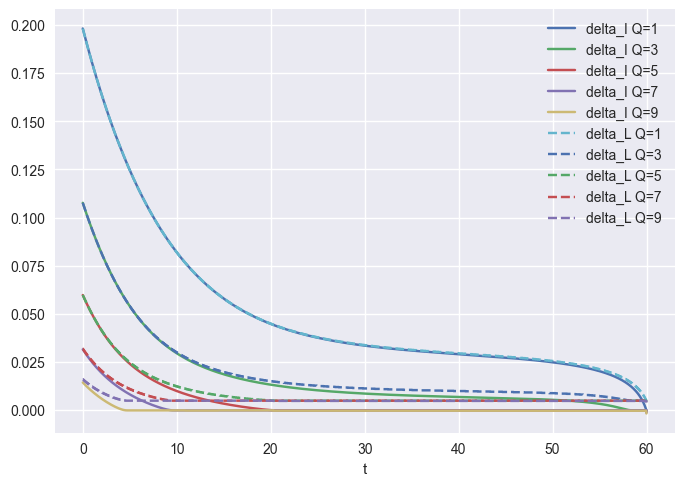

In [11]:
# The first df_delta graph (solid lines)
df_delta_i = pd.DataFrame({'t': t})
for i, d in enumerate(delta_i):
    title = f'delta_I Q={i}'
    df_delta_i[title] = d
columns_to_select_i = ['delta_I Q=1', 'delta_I Q=3', 'delta_I Q=5', 'delta_I Q=7', 'delta_I Q=9']
ax = df_delta_i.plot(x='t', y=columns_to_select_i, linestyle='-', ax=None)

# The second df_delta graph (dashed lines)
df_delta_l = pd.DataFrame({'t': t})
for i, d in enumerate(delta_l):
    title = f'delta_L Q={i}'
    df_delta_l[title] = d
    
columns_to_select_l = ['delta_L Q=1', 'delta_L Q=3', 'delta_L Q=5', 'delta_L Q=7', 'delta_L Q=9']
df_delta_l.plot(x='t', y=columns_to_select_l, linestyle='--', ax=ax)
# Display the graph
plt.savefig('delta_limitorder.pdf', format='pdf') 
plt.show()



In [12]:
# 必要な行を抽出
rows_to_select = [10, 20, 30, 40, 50]  # t の値を指定
filtered_df_l = df_delta_l[df_delta_l['t'].isin(rows_to_select)]
filtered_df_i = df_delta_i[df_delta_i['t'].isin(rows_to_select)]

# 必要な列を抽出
result_df_l = filtered_df_l[['t']+columns_to_select_l]
result_df_i = filtered_df_i[['t']+columns_to_select_i]

# 結果を表示
display(result_df_l)
display(result_df_i)


,t,delta_L Q=1,delta_L Q=3,delta_L Q=5,delta_L Q=7,delta_L Q=9
1000,10.0,0.081970,0.029968,0.012390,0.004944,0.004944
2000,20.0,0.044861,0.015076,0.005066,0.004944,0.004944
3000,30.0,0.033752,0.011292,0.004944,0.004944,0.004822
4000,40.0,0.029480,0.009949,0.004944,0.004944,0.004822
5000,50.0,0.025574,0.008850,0.004944,0.004944,0.004822


,t,delta_I Q=1,delta_I Q=3,delta_I Q=5,delta_I Q=7,delta_I Q=9
1000,10.0,0.081992,0.029569,0.009957,-0.000100,-0.000100
2000,20.0,0.044826,0.013250,0.000050,-0.000100,-0.000100
3000,30.0,0.033528,0.008625,-0.000100,-0.000183,-0.000237
4000,40.0,0.029098,0.006878,-0.000100,-0.000183,-0.000237
5000,50.0,0.024883,0.005404,-0.000100,-0.000100,-0.000280


In [13]:
# Value function comparison

h_lomo = -np.log(omega) / kappa

Q0 = Nq
S0 = 0.0
X0 = 0.0

H0_lomo = X0 + Q0 * S0 + h_lomo[Q0, 0]
H0_lomomm = X0 + Q0 * S0 + h2[Q0, 0]

value_comparison = pd.DataFrame({
    'Strategy': ['LO/MO', 'LO/MO/MM'],
    'Value at initial state': [H0_lomo, H0_lomomm]
})

value_comparison['Improvement over LO/MO'] = (
    value_comparison['Value at initial state'] - H0_lomo
)

display(value_comparison)


,Strategy,Value at initial state,Improvement over LO/MO
0,LO/MO,-0.041139,0.000000
1,LO/MO/MM,0.112355,0.153495


,lambda_I,H_LOMO,H_LOMOMM,improvement
0,0.333333,-0.041139,0.062264,0.103403
1,0.666667,-0.041139,0.090276,0.131415
2,1.000000,-0.041139,0.112355,0.153495
3,1.333333,-0.041139,0.130370,0.171509
4,1.666667,-0.041139,0.145538,0.186678


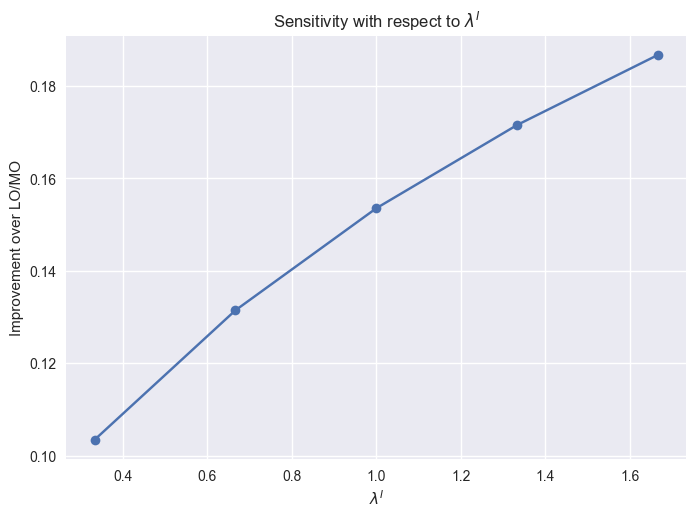

<Figure size 800x550 with 0 Axes>

In [14]:
# Sensitivity analysis: lambda^I

lambdaI_grid = [20/60, 40/60, 60/60, 80/60, 100/60]

rows = []

for lambI_value in lambdaI_grid:
    h_tmp, exe_tmp, delta_l_tmp, delta_i_tmp, zeta_tmp = oeh.hjb_solver_mm(
        t, dt, kappa, xi, phi,
        q, qAC,
        lambL, lambI_value,
        alpha, alphaL,
        alphaM, betaM
    )

    H0_lomomm_tmp = X0 + Q0 * S0 + h_tmp[Q0, 0]

    rows.append({
        "lambda_I": lambI_value,
        "H_LOMO": H0_lomo,
        "H_LOMOMM": H0_lomomm_tmp,
        "improvement": H0_lomomm_tmp - H0_lomo
    })

df_lambdaI = pd.DataFrame(rows)
display(df_lambdaI.round(6))

ax = df_lambdaI.plot(x="lambda_I", y="improvement", marker="o", legend=False)
ax.set_xlabel(r"$\lambda^I$")
ax.set_ylabel("Improvement over LO/MO")
ax.set_title(r"Sensitivity with respect to $\lambda^I$")
ax.grid(True)
plt.show()

plt.savefig("sensitivity.pdf", bbox_inches="tight")

,phi,H_LOMO,H_LOMOMM,improvement
0,0.00025,-0.072251,0.147240,0.219491
1,0.00050,-0.056538,0.130043,0.186581
2,0.00100,-0.041139,0.112355,0.153495
3,0.00200,-0.023608,0.091985,0.115594
4,0.00400,-0.000898,0.065818,0.066716


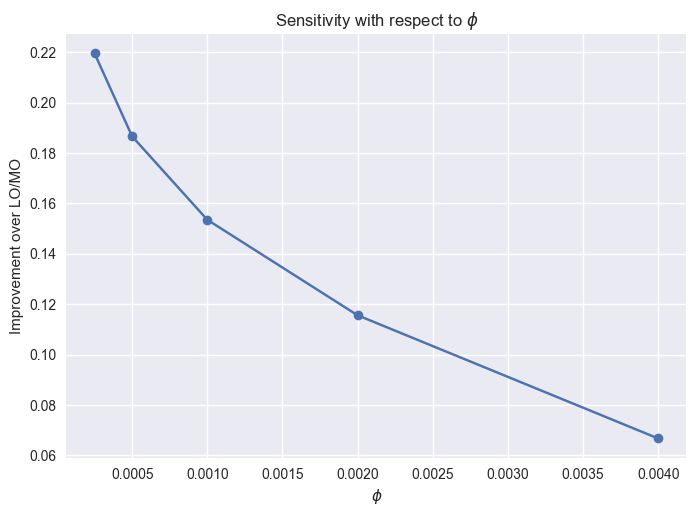

<Figure size 800x550 with 0 Axes>

In [15]:
# Sensitivity analysis: phi
# For phi, both LO/MO and LO/MO/MM are recomputed.

phi_grid = [0.00025, 0.0005, 0.001, 0.002, 0.004]

rows = []

for phi_value in phi_grid:
    omega_tmp, exe_tmp = oeh.hjb_solver(
        t, dt, kappa, xi, phi_value,
        q, qAC, lambL, alpha
    )

    h_lomo_tmp = -np.log(omega_tmp) / kappa
    H0_lomo_tmp = X0 + Q0 * S0 + h_lomo_tmp[Q0, 0]

    h_tmp, exe2_tmp, delta_l_tmp, delta_i_tmp, zeta_tmp = oeh.hjb_solver_mm(
        t, dt, kappa, xi, phi_value,
        q, qAC,
        lambL, lambI,
        alpha, alphaL,
        alphaM, betaM
    )

    H0_lomomm_tmp = X0 + Q0 * S0 + h_tmp[Q0, 0]

    rows.append({
        "phi": phi_value,
        "H_LOMO": H0_lomo_tmp,
        "H_LOMOMM": H0_lomomm_tmp,
        "improvement": H0_lomomm_tmp - H0_lomo_tmp
    })

df_phi = pd.DataFrame(rows)
display(df_phi.round(6))

ax = df_phi.plot(x="phi", y="improvement", marker="o", legend=False)
ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Improvement over LO/MO")
ax.set_title(r"Sensitivity with respect to $\phi$")
ax.grid(True)
plt.show()
plt.savefig("sensitivity_phi.pdf", bbox_inches="tight")

,alpha_M,H_LOMO,H_LOMOMM,improvement
0,0.000025,-0.041139,0.112360,0.153500
1,0.000050,-0.041139,0.112358,0.153498
2,0.000100,-0.041139,0.112355,0.153495
3,0.000200,-0.041139,0.112349,0.153488
4,0.000400,-0.041139,0.112337,0.153477


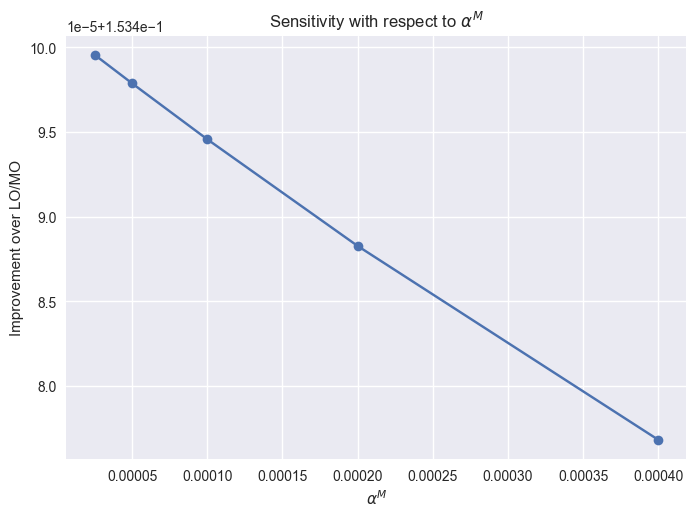

In [16]:
# Sensitivity analysis: alpha^M

alphaM_grid = [0.000025, 0.00005, 0.0001, 0.0002, 0.0004]

rows = []

for alphaM_value in alphaM_grid:
    h_tmp, exe_tmp, delta_l_tmp, delta_i_tmp, zeta_tmp = oeh.hjb_solver_mm(
        t, dt, kappa, xi, phi,
        q, qAC,
        lambL, lambI,
        alpha, alphaL,
        alphaM_value, betaM
    )

    H0_lomomm_tmp = X0 + Q0 * S0 + h_tmp[Q0, 0]

    rows.append({
        "alpha_M": alphaM_value,
        "H_LOMO": H0_lomo,
        "H_LOMOMM": H0_lomomm_tmp,
        "improvement": H0_lomomm_tmp - H0_lomo
    })

df_alphaM = pd.DataFrame(rows)
display(df_alphaM.round(6))

ax = df_alphaM.plot(x="alpha_M", y="improvement", marker="o", legend=False)
ax.set_xlabel(r"$\alpha^M$")
ax.set_ylabel("Improvement over LO/MO")
ax.set_title(r"Sensitivity with respect to $\alpha^M$")
ax.grid(True)
plt.show()


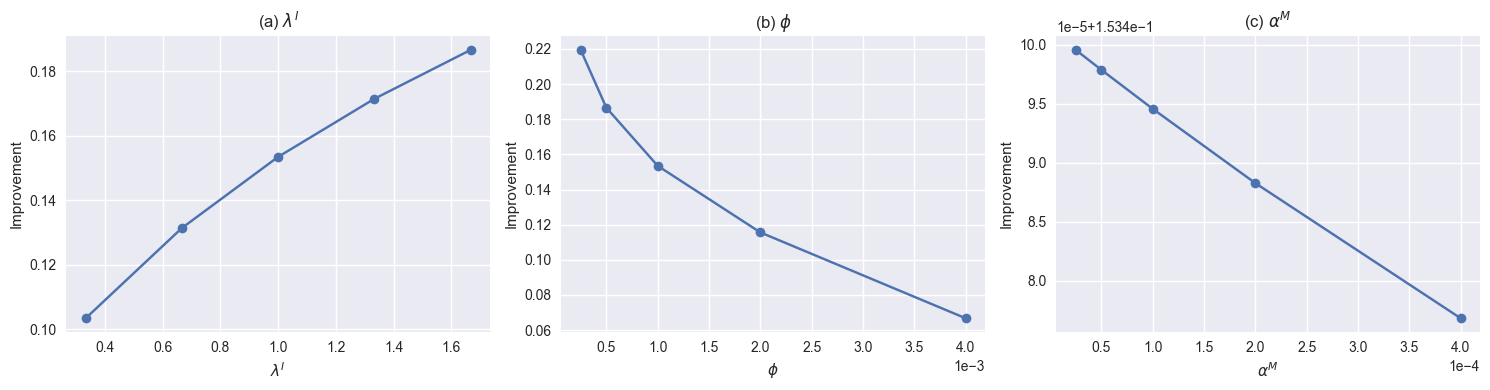

In [21]:
# ============================================================
# Combined sensitivity figure
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ============================================================
# (a) lambda^I
# ============================================================

axes[0].plot(
    df_lambdaI["lambda_I"],
    df_lambdaI["improvement"],
    marker="o"
)

axes[0].set_xlabel(r"$\lambda^I$")
axes[0].set_ylabel("Improvement")
axes[0].set_title(r"(a) $\lambda^I$")
axes[0].grid(True)


# ============================================================
# (b) phi
# ============================================================

axes[1].plot(
    df_phi["phi"],
    df_phi["improvement"],
    marker="o"
)

axes[1].ticklabel_format(
    style='sci',
    axis='x',
    scilimits=(0,0)
)

axes[1].set_xlabel(r"$\phi$")
axes[1].set_ylabel("Improvement")
axes[1].set_title(r"(b) $\phi$")
axes[1].grid(True)


# ============================================================
# (c) alpha^M
# ============================================================

axes[2].plot(
    df_alphaM["alpha_M"],
    df_alphaM["improvement"],
    marker="o"
)

axes[2].ticklabel_format(
    style='sci',
    axis='x',
    scilimits=(0,0)
)

axes[2].set_xlabel(r"$\alpha^M$")
axes[2].set_ylabel("Improvement")
axes[2].set_title(r"(c) $\alpha^M$")
axes[2].grid(True)


# ============================================================
# Layout and save
# ============================================================

plt.tight_layout()

fig.savefig(
    "sensitivity_all.pdf",
    bbox_inches="tight"
)

plt.show()